In [4]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

df = pd.read_csv(
    "data/household_power_consumption.txt",
    sep=";",  # the file uses semicolons, not commas
    na_values="?", #missing reading are stored as "?"
    low_memory=False,
)
print(df.head())
print(df.shape)

         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  
(2075259, 9)


In [5]:
df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S")
df = df.set_index("datetime")

power = df["Global_active_power"].astype(float)
print(power.describe())
print("Share of missing minutes:", power.isna().mean())

count    2.049280e+06
mean     1.091615e+00
std      1.057294e+00
min      7.600000e-02
25%      3.080000e-01
50%      6.020000e-01
75%      1.528000e+00
max      1.112200e+01
Name: Global_active_power, dtype: float64
Share of missing minutes: 0.012518437457686004


In [6]:
hourly = power.resample("h").mean()

In [7]:
table = hourly.to_frame("kw")
table["date"] = table.index.date
table["hour"] = table.index.hour

days = table.pivot(index="date", columns="hour", values="kw")
print("Before dropping incomplete days:", days.shape)

days = days.dropna()   # throw away any day with a missing hour
print("After:", days.shape)

days.to_csv("data/days.csv")

Before dropping incomplete days: (1442, 24)
After: (1417, 24)


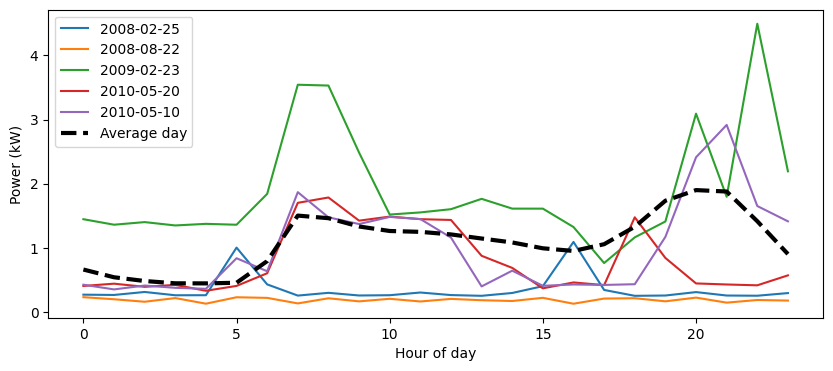

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
for date in days.sample(5, random_state=0).index:
    ax.plot(range(24), days.loc[date], label=str(date))
ax.plot(range(24), days.mean(), "k--", linewidth=3, label="Average day")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Power (kW)")
ax.legend()
plt.show()

In [10]:
print(days.values.max())

6.560533333333334
